In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy.optimize import curve_fit

In [2]:
df=pd.read_csv("advertising.csv")

In [3]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


## initial data inspection

In [198]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [199]:
df.duplicated().sum()

np.int64(0)

In [200]:
#df.describe()

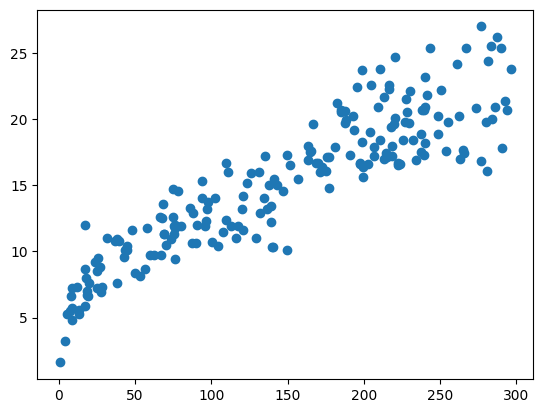

In [201]:
plt.scatter(df.TV,df.Sales)

## Exploratory Data analysis(EDA)

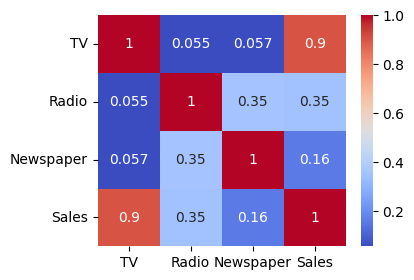

In [4]:
import seaborn as sns
plt.figure(figsize=(4,3))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')
plt.show()

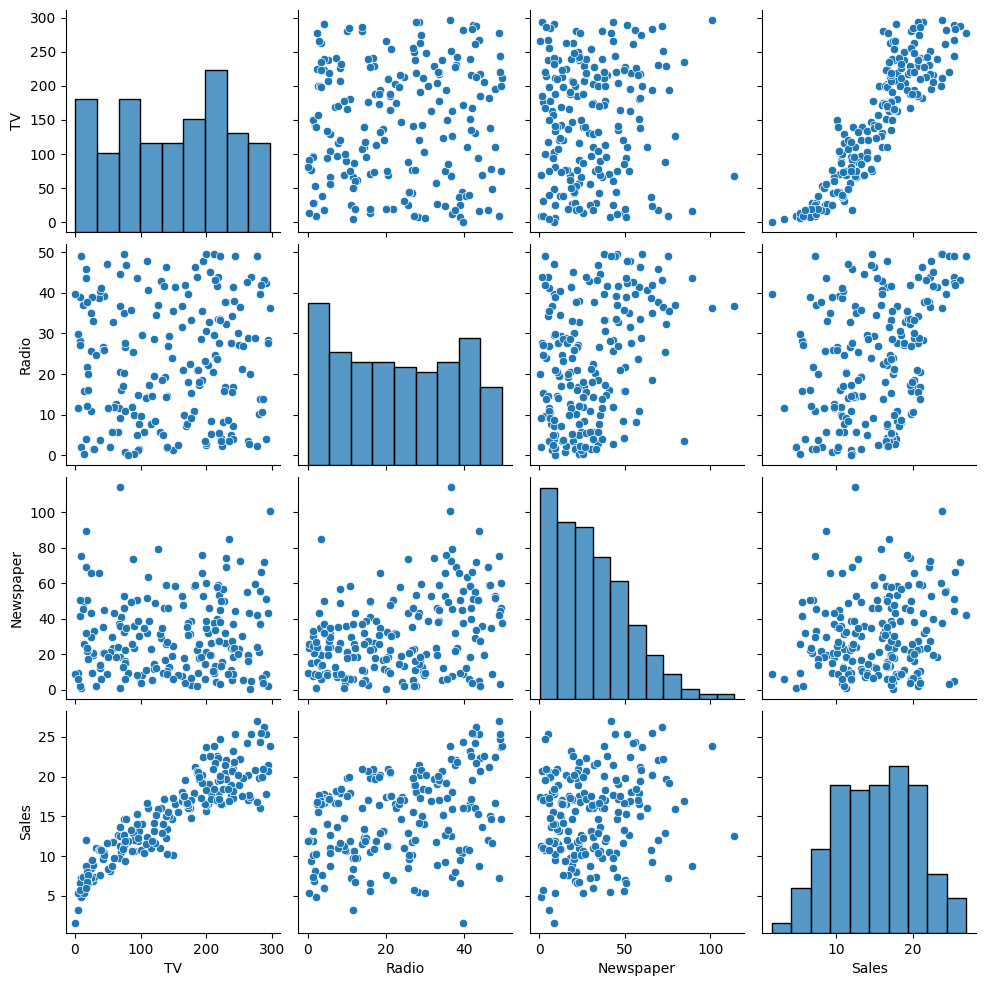

In [5]:
sns.pairplot(df)
plt.show()

##  Defining the Nonlinear Regression Function

In [83]:
def sqrt(x,a,c):
    y=a*np.sqrt(x)+c
    return y
    

In [84]:
def da2(x,d,e,f):
    y=d*(x**2) + e*(x) + f
    return y     

In [89]:
def nonlinear(x,a,c,d,e,f):
    x1=x[:,0]
    x2=x[:,1]
    ymodel=sqrt(x1,a,c)+da2(x2,d,e,f)
    return(ymodel)     

## train test split

In [90]:
from sklearn.model_selection import train_test_split
# Sample data
X=df[['TV','Radio']]
Y =df['Sales']
# Splitting data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
len(y_test)

40

In [91]:
xtrain1=x_train["TV"].to_numpy()
xtrain2=x_train["Radio"].to_numpy()
ytrain=y_train.to_numpy()
xtrain=np.column_stack((xtrain1,xtrain2))
xtest1=x_test["TV"].to_numpy()
xtest2=x_test["Radio"].to_numpy()
xtest=np.column_stack((xtest1,xtest2))
ytest=y_test.to_numpy()
len(xtest)

40

## estimating parameters

In [92]:
popt, pcov = curve_fit(nonlinear,xtrain, ytrain)
print(popt)

[ 1.15869728e+00 -7.34542939e+04  1.75063509e-03  2.56084948e-02
  7.34543350e+04]


## model evaluation

In [93]:
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
y_train_pred=nonlinear(xtrain,*popt)
r2_train=r2_score(ytrain,y_train_pred)
print("R2-scoretrain: %.3f" % r2_score(ytrain , y_train_pred) )
print("Mean absolute error: %.3f" % np.mean(np.absolute(y_train_pred-ytrain)))
print("Mean squared error (MSE): %.3f" % np.mean((y_train_pred-ytrain) ** 2))
rmse = np.sqrt(mean_squared_error(ytrain,y_train_pred))
print("rmse: %.3f" %rmse)
len(y_train_pred)

R2-scoretrain: 0.925
Mean absolute error: 1.109
Mean squared error (MSE): 2.021
rmse: 1.422


160

In [94]:
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
y_pred = nonlinear(xtest,*popt)
print("Mean absolute error: %.3f" % np.mean(np.absolute(y_pred-ytest)))
print("Mean squared error (MSE): %.3f" % np.mean((y_pred-ytest) ** 2))
print("R2-score: %.3f" % r2_score(ytest , y_pred) )
rmse = np.sqrt(mean_squared_error(ytest,y_pred))
print("rmse: %.3f" %rmse)
len(y_pred)

Mean absolute error: 0.923
Mean squared error (MSE): 1.596
R2-score: 0.948
rmse: 1.263


40

## cross validation

In [95]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.optimize import curve_fit
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

mae_scores = []
mse_scores = []
rmse_scores = []
r2_scores = []

for train_idx, val_idx in kf.split(x_train):

    X_train_cv = x_train.iloc[train_idx]
    X_val_cv = x_train.iloc[val_idx]

    y_train_cv = y_train.iloc[train_idx]
    y_val_cv = y_train.iloc[val_idx]

    # تخمین پارامترها فقط با داده‌های Train این Fold
    params, _ = curve_fit(
        nonlinear,
        X_train_cv.values,
        y_train_cv.values
    )

    # پیش‌بینی روی Validation
    y_predict = nonlinear(
        X_val_cv.values,
        *params
    )

    # ارزیابی
    mae_scores.append(
        mean_absolute_error(y_val_cv, y_predict)
    )

    mse_scores.append(
        mean_squared_error(y_val_cv, y_predict)
    )

    rmse_scores.append(
        np.sqrt(mean_squared_error(y_val_cv, y_predict))
    )

    r2_scores.append(
        r2_score(y_val_cv, y_predict)
    )    

In [96]:
for fold, (train_idx, val_idx) in enumerate(kf.split(x_train), start=1):

    X_train_cv = x_train.iloc[train_idx]
    X_val_cv = x_train.iloc[val_idx]

    y_train_cv = y_train.iloc[train_idx]
    y_val_cv = y_train.iloc[val_idx]

    params, _ = curve_fit(
        nonlinear,
        X_train_cv.values,
        y_train_cv.values
    )

    y_predict = nonlinear(X_val_cv.values, *params)

    r2 = r2_score(y_val_cv, y_predict)

    print(f"Fold {fold}:")
    print("R2 =", r2)
    print("MAE =", mean_absolute_error(y_val_cv, y_predict))
    print("MSE =", mean_squared_error(y_val_cv, y_predict))
    print( "RMSE =", np.sqrt(mean_squared_error(y_val_cv, y_predict)))
    print("Std y:", y_val_cv.std())
    print("Validation samples =", len(y_val_cv))
    print("y mean:", y_val_cv.mean())
    print("y min:", y_val_cv.min())
    print("y max:", y_val_cv.max())
    print("Actual:")
    print(y_val_cv.values)
    print("\nPredicted:")
    print(y_predict)
    print("\nError:")
    print(y_val_cv.values - y_predict)
mean_r2 = np.mean(r2_scores)
std_r2 = np.std(r2_scores, ddof=1)
print(mean_r2)     
print(std_r2)

Fold 1:
R2 = 0.8511988500071924
MAE = 1.138881894879705
MSE = 2.3159968989193045
RMSE = 1.5218399715210875
Std y: 4.008297844834291
Validation samples = 32
y mean: 13.9
y min: 7.2
y max: 22.6
Actual:
[12.   7.2 11.  10.9  7.6 16.7 17.8  9.5 10.7 11.9 19.2 17.3 12.9 12.6
 15.2 18.  17.  17.9 15.  21.2 15.5 16.8 11.8 11.9  7.3 14.  12.9  9.7
 22.6 10.1 12.2 18.4]

Predicted:
[12.14595244  8.93648503 13.44461102 10.84112915  6.24504528 16.52540159
 20.07092434  9.52892122 12.03391369 10.42966328 19.37226603 17.42173355
 14.39038604  9.62535271 15.92222141 18.26423302 19.06681395 17.1116135
 18.78161942 20.82664351 14.68091801 19.52701034 12.05298263 11.43256065
  6.210198   11.44668607 12.68112731  9.46882784 21.37687089  9.52289622
 14.43327465 18.12419416]

Error:
[-0.14595244 -1.73648503 -2.44461102  0.05887085  1.35495472  0.17459841
 -2.27092434 -0.02892122 -1.33391369  1.47033672 -0.17226603 -0.12173355
 -1.49038604  2.97464729 -0.72222141 -0.26423302 -2.06681395  0.7883865
 -3.7816

## 3D Visualization of Model Predictions on Training and Test Data

In [97]:
TV_grid = np.linspace(x_train["TV"].min(), x_train["TV"].max(), 50)
Radio_grid = np.linspace(x_train["Radio"].min(), x_train["Radio"].max(), 50)
TV_mesh, Radio_mesh = np.meshgrid(TV_grid, Radio_grid)
X_grid = np.column_stack((
    TV_mesh.ravel(),
    Radio_mesh.ravel()
))
Sales_pred = nonlinear(X_grid, *popt)
Sales_mesh = Sales_pred.reshape(TV_mesh.shape)

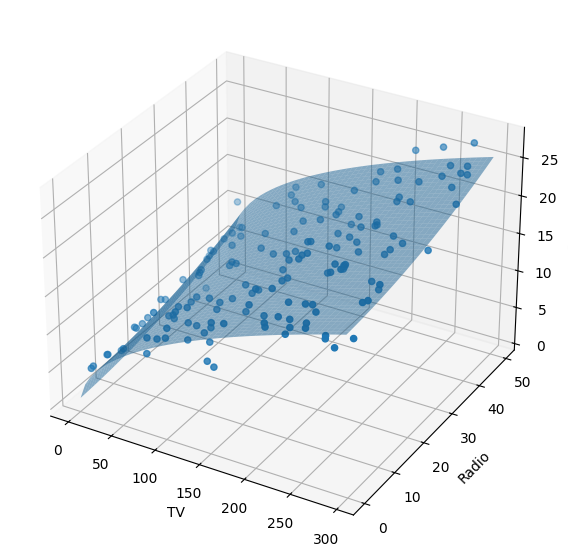

In [98]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
# داده‌های واقعی
ax.scatter(
    x_train["TV"],
    x_train["Radio"],
    y_train
)
# سطح مدل
ax.plot_surface(
    TV_mesh,
    Radio_mesh,
    Sales_mesh,
    alpha=0.5
)
ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Sales")
plt.show()

In [99]:
TV_grid = np.linspace(x_test["TV"].min(), x_test["TV"].max(), 50)
Radio_grid = np.linspace(x_test["Radio"].min(), x_test["Radio"].max(), 50)
TV_mesh, Radio_mesh = np.meshgrid(TV_grid, Radio_grid)
X_grid = np.column_stack((
    TV_mesh.ravel(),
    Radio_mesh.ravel()
))
Sales_pred = nonlinear(X_grid, *popt)
Sales_mesh = Sales_pred.reshape(TV_mesh.shape)

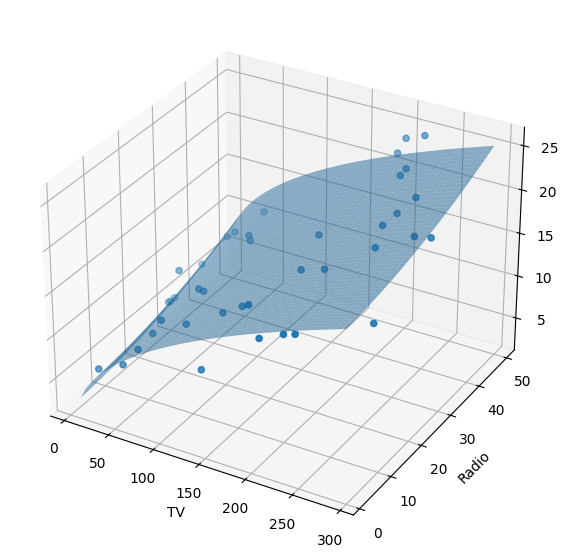

In [100]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
# داده‌های واقعی
ax.scatter(
    x_test["TV"],
    x_test["Radio"],
    y_test
)
# سطح مدل
ax.plot_surface(
    TV_mesh,
    Radio_mesh,
    Sales_mesh,
    alpha=0.5
)
ax.set_xlabel("TV")
ax.set_ylabel("Radio")
ax.set_zlabel("Sales")
plt.show()

## Residual analysis

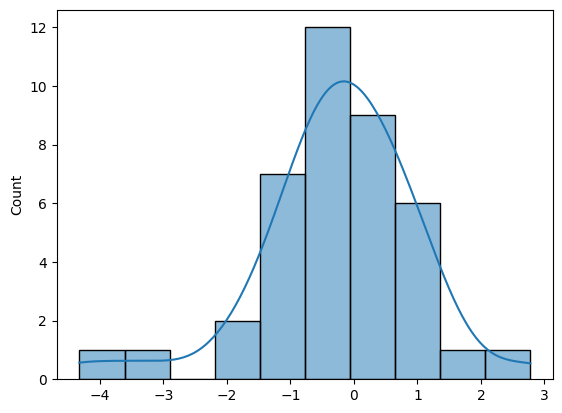

In [51]:
import seaborn as sns
residuals = ytest - y_pred
sns.histplot(residuals,kde=True)
plt.show()

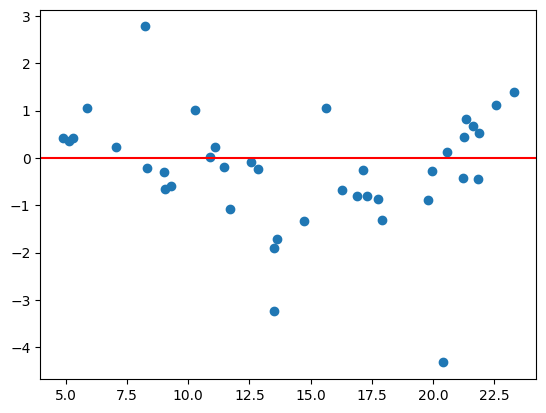

In [52]:
plt.scatter(y_pred,residuals)
plt.axhline(y=0,color='red')
plt.show()

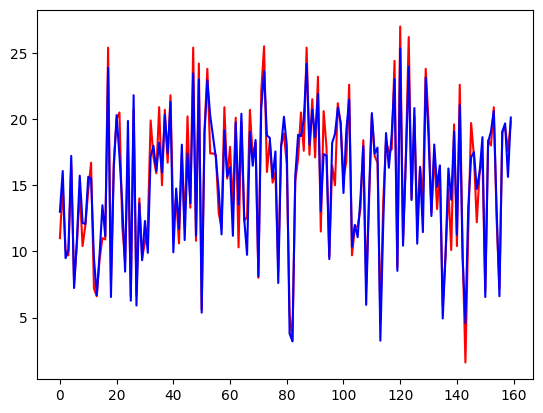

In [53]:
yytrain=y_train.tolist()
yytrainpred=y_train_pred.tolist()
plt.plot(yytrain,'r-',yytrainpred,'b-')

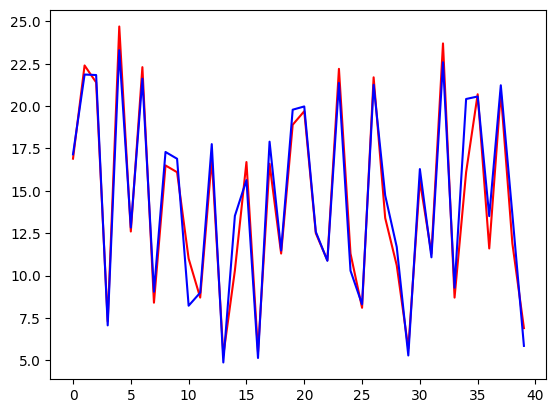

In [54]:
yytrain=y_test.tolist()
yytrainpred=y_pred.tolist()
plt.plot(yytrain,'r-',yytrainpred,'b-')